# Geometric Deep Learning

This notebook is part of the lab semiar [Machine Learning and AI in the Life Sciences: Methods and Applications](https://www.fu-berlin.de/vv/de/lv/935203) at Freie Universität Berlin.

In this practical we will implement a graph convolutional network and apply it to the problem of graph-level prediction of the properties of drug-like molecules.

## Setup environment

Let's install the required python packages. We will be working with the [`jax` library](https://docs.jax.dev/en/latest/index.html) and its ecosystem of deep learning tools.

In [ ]:
%%capture
!pip install ipdb
!pip install jax jraph flax optax torch-geometric

# QM9 Dataset

We will work with the QM9 dataset that is a benchmark database used in machine learning for molecular properties. It contains data for 133k small organic molecules with 19 regression targets. We can use the PyG libraray to load the molecules as graphs equpped with a number of pre-computed features:

**Atom features (`G.x`)** - $\mathbb{R}^{|V| \times 11}$
- 1st-5th features: Atom type (one-hot: H, C, N, O, F)
- 6th feature (also `data.z`): Atomic number (number of protons).
- 7th feature: Aromatic (binary)
- 8th-10th features: Electron orbital hybridization (one-hot: sp, sp2, sp3)
- 11th feature: Number of hydrogens

**Edge Index (`G.edge_index`)** - $\mathbb{R}^{2×|E|}$
- A tensor of dimensions 2 x `G.num_edges` that describe the edge connectivity of the graph

**Edge features (`G.edge_attr`)** - $\mathbb{R}^{|E|\times 4}$
- 1st-4th features: bond type (one-hot: single, double, triple, aromatic)

**Atom positions (`G.pos`)** - $\mathbb{R}^{|V|\times 3}$
- 3D coordinates of each atom.

**Target (`G.y`)** - $\mathbb{R}^{19}$

| Target | Property                      | Unit         | Description                                              |
|--------|-------------------------------|--------------|----------------------------------------------------------|
| 0      | $\mu$                         | D            | Dipole moment                                            |
| 1      | $\alpha$                      | $a_0^3$      | Isotropic polarizability                                |
| 2      | $\epsilon_{\textrm{HOMO}}$    | eV           | Highest occupied molecular orbital energy                |
| 3      | $\epsilon_{\textrm{LUMO}}$    | eV           | Lowest unoccupied molecular orbital energy               |
| 4      | $\Delta \epsilon$             | eV           | Gap between $\epsilon_{\textrm{HOMO}}$ and $\epsilon_{\textrm{LUMO}}$ |
| 5      | $\langle R^2 \rangle$         | $a_0^2$      | Electronic spatial extent                                |
| 6      | ZPVE                          | eV           | Zero point vibrational energy                            |
| 7      | $U_0$                         | eV           | Internal energy at 0K                                    |
| 8      | $U$                           | eV           | Internal energy at 298.15K                               |
| 9      | $H$                           | eV           | Enthalpy at 298.15K                                      |
| 10     | $G$                           | eV           | Free energy at 298.15K                                   |
| 11     | $c_{\textrm{v}}$              | cal/mol·K    | Heat capacity at 298.15K                                 |
| 12     | $U_0^{\textrm{ATOM}}$         | eV           | Atomization energy at 0K                                 |
| 13     | $U^{\textrm{ATOM}}$           | eV           | Atomization energy at 298.15K                            |
| 14     | $H^{\textrm{ATOM}}$           | eV           | Atomization enthalpy at 298.15K                          |
| 15     | $G^{\textrm{ATOM}}$           | eV           | Atomization free energy at 298.15K                       |
| 16     | $A$                           | GHz          | Rotational constant                                      |
| 17     | $B$                           | GHz          | Rotational constant                                      |
| 18     | $C$                           | GHz          | Rotational constant                                      |



In [ ]:
from typing import NamedTuple

import torch
from torch_geometric.datasets import QM9
import torch_geometric.transforms as T
from torch_geometric.utils import remove_self_loops

import numpy as np
import jax
import jax.numpy as jnp
import optax

class SetTarget(NamedTuple):
    target: int = 0
    """
    Only keep the label for a specific target (there are 19 targets in QM9).
    """
    def __call__(self, data):
        data.y = data.y[:, self.target]
        return data

# Transforms which are applied during data loading:
transform = SetTarget(0)

# Define our dataset, using torch datasets
qm9_dataset = QM9('./qm9/', transform=transform)
print(f"Total number of samples: {len(qm9_dataset)}.")

# Split datasets (subset of full dataset for efficiency)
train_dataset = qm9_dataset[:1000]
val_dataset = qm9_dataset[1000:2000]
test_dataset = qm9_dataset[2000:3000]
print(f"Created dataset splits with {len(train_dataset)} training, {len(val_dataset)} validation, {len(test_dataset)} test samples.")


Extracting qm9/raw/qm9_v3.zip
Processing...
Using a pre-processed version of the dataset. Please install 'rdkit' to alternatively process the raw data.
Done!


Total number of samples: 130831.
Created dataset splits with 1000 training, 1000 validation, 1000 test samples.


# Representing and batching graphs with `jraph`

> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Convert graph representation from `torch_geometric.data.Data` to `jraph.GraphsTuple` for use in `jax`

In [ ]:
import torch_geometric
from typing import List, Generator
from torch.utils.data import DataLoader, default_collate

import jraph

MAX_NUM_NODES = 29
MAX_NUM_EDGES = 56
TYPE = jnp.float32

def jraph_iterate(data: List[torch_geometric.data.Data]) -> Generator[jraph.GraphsTuple, None, None]:
    for G in data:
        nodes = jnp.array(G.x)
        edges = jnp.array(G.edge_attr)
        senders = jnp.array(G.edge_index[0])
        receivers = jnp.array(G.edge_index[1])
        globals_ = jnp.array(G.y)

        #print(globals_.shape)
        n_node = jnp.array([G.num_nodes])
        n_edge = jnp.array([G.num_edges])

        graph= jraph.GraphsTuple(
            nodes=nodes,
            edges=edges,
            senders=senders,
            receivers=receivers,
            globals=globals_,
            n_node=n_node,
            n_edge=n_edge,
        )
        yield graph

def jraph_collate(batch: List[torch_geometric.data.Data]) -> Generator[jraph.GraphsTuple, None, None]:
  """
  Collate function specifies how to combine a list of data samples into a batch.
  default_collate creates pytorch tensors, then tree_map converts them into numpy arrays.
  """
  batch_size = len(batch)
  return next(jraph.dynamically_batch(
        jraph_iterate(batch),
        n_node=batch_size * MAX_NUM_NODES + 1, # Plus one for the extra padding node.
        n_edge=batch_size * MAX_NUM_EDGES,
        n_graph=batch_size + 1))


training_generator = DataLoader(qm9_dataset, batch_size=5, collate_fn=jraph_collate)

# Create pytorch data loader with custom collate function
train_loader = DataLoader(train_dataset, batch_size=32, collate_fn=jraph_collate, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, collate_fn=jraph_collate, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, collate_fn=jraph_collate, shuffle=False)

In [ ]:
#print(train_dataset[0].y.shape)

# Graph convolutional layer


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Implement the graph convolution module stub given below
> * Create and run a unit test that checks the equivariance of your module


**TIP:** Note that you will have to implement the __call__ function of a `nn.Module` but you will have to use `init` and `apply` to apply it to a data.

In [ ]:
import flax.linen as nn
from typing import Callable

class GraphConvolution(nn.Module):
    psi: nn.Module
    phi: nn.Module

    @nn.compact
    def __call__(self, G: jraph.GraphsTuple) -> jraph.GraphsTuple:
      x = G.nodes

      # TODO: Your code here
      senders = G.senders              # shape (num_edges,)
      receivers = G.receivers          # shape (num_edges,)

      # Message from sender nodes: apply psi to all nodes
      msg = self.psi(x)                # shape (num_nodes, msg_dim)
      # Gather messages for each edge
      edge_msg = msg[senders]          # (num_edges, msg_dim)

      # Aggregate messages for each receiver node (sum aggregation)
      node_incoming_msg = jax.ops.segment_sum(edge_msg, receivers, x.shape[0])
      # Combine old node features and incoming messages with phi
      x = self.phi(jnp.concatenate([x, node_incoming_msg], axis=-1))

      return G._replace(nodes=x)

In [ ]:
#example graph (just one, first from the data)
pyg_graph = train_dataset[0]
G = next(jraph_iterate([pyg_graph]))

#one layer
psi = nn.Dense(8)
phi = nn.Dense(8)
graphconv = GraphConvolution(psi=psi, phi=phi)
rng = jax.random.PRNGKey(0)
params = graphconv.init(rng, G)

#Generates a random permutation of the node indices to simulate a different node ordering.
num_nodes = G.nodes.shape[0]
perm = jax.random.permutation(jax.random.PRNGKey(123), num_nodes)
nodes_perm = G.nodes[perm]
#Builds a reverse map: tells you where each original node ends up after permutation. -> Needed to adjust sender and receiver indices accordingly.
node_map = jnp.zeros(num_nodes, dtype=jnp.int32).at[perm].set(jnp.arange(num_nodes))
#Applies the permutation to the edge indices, so that the edges still connect the same logical nodes (just under different indices).
senders_perm = node_map[G.senders]
receivers_perm = node_map[G.receivers]
#Constructs a new graph G_perm that is the permuted version of G — same structure, different node ordering.
G_perm = G._replace(
    nodes=nodes_perm,
    senders=senders_perm,
    receivers=receivers_perm,
)

#Applies the graph convolution layer to both the original and the permuted graph.
G_out = graphconv.apply(params, G)
G_perm_out = graphconv.apply(params, G_perm)

#Applies the same permutation to the output of the original graph so that its node order matches that of the permuted graph's output.
G_out_nodes_perm = G_out.nodes[perm]
#Compares the node outputs: if the layer is permutation equivariant
assert jnp.allclose(G_out_nodes_perm, G_perm_out.nodes, atol=1e-5), "FAIL: Not equivariant!"
print("PASS: equivariance shown")


PASS: equivariance shown


# Graph convolutional network


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Implement an __invariant__ graph neural network based on your convolutional layer that regresses the graph-level target `G.y`
> * Create and run a unit test that checks the invariance of your module


In [ ]:
def get_graph_indices(n_node):

    return jnp.concatenate([jnp.full((n,), i) for i, n in enumerate(n_node)])

In [ ]:
class GCN(nn.Module):
    num_layers: int
    hidden_size: int

    @nn.compact
    def __call__(self, G: jraph.GraphsTuple) -> jraph.GraphsTuple:
        # TODO: implement a GCN for graph-level prediction
        for _ in range(self.num_layers):
            G = GraphConvolution(
                psi=nn.Dense(self.hidden_size),
                phi=nn.Dense(self.hidden_size),
            )(G)
        node_graph_idx = get_graph_indices(G.n_node)
        graph_embedding = jraph.segment_mean(G.nodes, node_graph_idx, G.n_node.shape[0])

        # Regression head
        return nn.Dense(1)(graph_embedding)

In [ ]:
#mini graph (take one from data)
pyg_graph = train_dataset[0]
#Converts the PyG graph to a JAX-compatible jraph.GraphsTuple using your custom iterator.
G = next(jraph_iterate([pyg_graph]))

#Initializes a small GCN model with 2 graph convolutional layers and 8-dimensional hidden features.
model = GCN(num_layers=2, hidden_size=8)
rng = jax.random.PRNGKey(0)
params = model.init(rng, G)

#Generates a random permutation of node indices to simulate different node orderings in the graph.
num_nodes = G.nodes.shape[0]
perm = jax.random.permutation(jax.random.PRNGKey(123), num_nodes)
#Applies the permutation to reorder the node feature matrix accordingly.
nodes_perm = G.nodes[perm]
#Creates a reverse lookup to map from permuted indices back to original positions. -> Essential for correctly updating the edge indices to reflect the new node order.
node_map = jnp.zeros(num_nodes, dtype=jnp.int32).at[perm].set(jnp.arange(num_nodes))
#Applies the reverse mapping to the edge connections, so edges still connect the same logical nodes (even though their indices are now permuted).
senders_perm = node_map[G.senders]
receivers_perm = node_map[G.receivers]
#Constructs the permuted graph G_perm with the updated node and edge data.
G_perm = G._replace(
    nodes=nodes_perm,
    senders=senders_perm,
    receivers=receivers_perm,
)

#Feeds both the original and the permuted graph into the GCN.
pred_orig = model.apply(params, G)
pred_perm = model.apply(params, G_perm)

print("Prediction original:", pred_orig)
print("Prediction permuted:", pred_perm)
assert jnp.allclose(pred_orig, pred_perm, atol=1e-5), "FAIL: Model is not invariant!"
print("PASS: invariance shown")


Prediction original: [[2.7993348]]
Prediction permuted: [[2.7993348]]
PASS: invariance shown


# Predicting the electric dipole moment


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Train your model on (a subset of) the QM9 dataset
> * evaluate the performance of your model


In [ ]:
#ini
model = GCN(num_layers=4, hidden_size=128)

for batch in train_loader:
    example_batch = batch
    break

rng = jax.random.PRNGKey(0)
params = model.init(rng, example_batch)

#optimizer
optimizer = optax.adam(1e-4)
opt_state = optimizer.init(params)

# loss
def loss_base(params, batch):
    preds = model.apply(params, batch)
    targets = batch.globals
    return jnp.mean((preds.squeeze() - targets.squeeze()) ** 2)


#step of training (w. opt.)

def train_step(params, opt_state, batch):
    loss, grads = jax.value_and_grad(loss_base)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

#loop
num_epochs = 20
train_losses = []
global_val_losses = []

for epoch in range(num_epochs):
    epoch_losses = []
    for batch in train_loader:
        params, opt_state, loss = train_step(params, opt_state, batch)
        epoch_losses.append(loss)
    train_loss = jnp.mean(jnp.array(epoch_losses))

    #validation -maybe somehow use in the optimizer? idk
    val_losses = []
    for batch in val_loader:
        val_loss = loss_base(params, batch)
        val_losses.append(val_loss)
    val_loss = jnp.mean(jnp.array(val_losses))
    train_losses.append(train_loss)
    global_val_losses.append(val_loss)
    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}")


Epoch 1: Train Loss=318112672.0000, Val Loss=5227410.5000
Epoch 2: Train Loss=3222095.0000, Val Loss=166128.9688
Epoch 3: Train Loss=71688.8750, Val Loss=8051.1880
Epoch 4: Train Loss=3933.0220, Val Loss=205.2887
Epoch 5: Train Loss=134.4905, Val Loss=8.5618
Epoch 6: Train Loss=11.8602, Val Loss=7.4514
Epoch 7: Train Loss=5.2551, Val Loss=6.7539
Epoch 8: Train Loss=4.2270, Val Loss=5.5524
Epoch 9: Train Loss=3.6707, Val Loss=5.5586
Epoch 10: Train Loss=3.7435, Val Loss=5.8870
Epoch 11: Train Loss=3.7250, Val Loss=5.4764
Epoch 12: Train Loss=3.5942, Val Loss=5.2431
Epoch 13: Train Loss=3.7666, Val Loss=5.4568
Epoch 14: Train Loss=3.8067, Val Loss=7.7050
Epoch 15: Train Loss=3.6107, Val Loss=6.0331
Epoch 16: Train Loss=3.4133, Val Loss=7.7807
Epoch 17: Train Loss=4.0975, Val Loss=5.3674
Epoch 18: Train Loss=3.5623, Val Loss=6.4921
Epoch 19: Train Loss=4.0656, Val Loss=5.0354
Epoch 20: Train Loss=3.5438, Val Loss=5.2851


In [ ]:
#eval on test
test_losses = []
for batch in test_loader:
    loss = loss_base(params, batch)
    test_losses.append(loss)
print(f"Test Loss: {jnp.mean(jnp.array(test_losses)):.4f}")

Test Loss: 4.6285


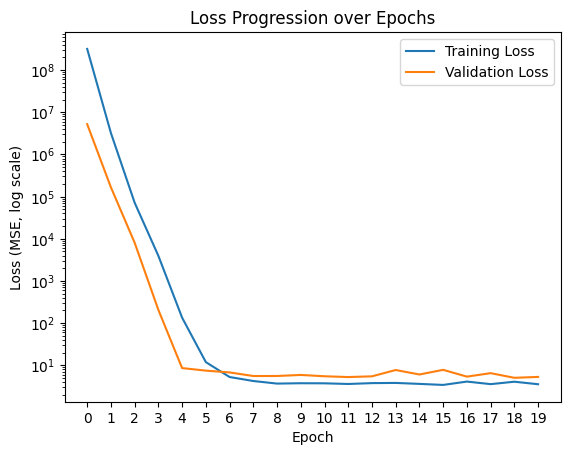

In [ ]:
import matplotlib.pyplot as plt


# Plot the curves
plt.plot(train_losses, label='Training Loss')
plt.plot(global_val_losses, label='Validation Loss')

plt.xticks(range(0, 20))
plt.yscale('log')

plt.xlabel('Epoch')
plt.ylabel('Loss (MSE, log scale)')
plt.legend()
plt.title("Loss Progression over Epochs")
plt.show()

In [ ]:
#ini
model = GCN(num_layers=4, hidden_size=128)

for batch in train_loader:
    example_batch = batch
    break

rng = jax.random.PRNGKey(0)
params = model.init(rng, example_batch)

#optimizer
optimizer = optax.adam(1e-4)
opt_state = optimizer.init(params)


def loss_mae(params, batch): #loss 2
    preds = model.apply(params, batch)
    targets = batch.globals
    return jnp.mean(jnp.abs(preds.squeeze() - targets.squeeze()))

#step of trainning (w. opt.)

def train_step(params, opt_state, batch):
    loss, grads = jax.value_and_grad(loss_mae)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

#loop
num_epochs = 20
train_losses = []
global_val_losses = []

for epoch in range(num_epochs):
    epoch_losses = []
    for batch in train_loader:
        params, opt_state, loss = train_step(params, opt_state, batch)
        epoch_losses.append(loss)
    train_loss = jnp.mean(jnp.array(epoch_losses))

    #validation -maybe somehow use in the optimizer? idk
    val_losses = []
    for batch in val_loader:
        val_loss = loss_mae(params, batch)
        val_losses.append(val_loss)
    val_loss = jnp.mean(jnp.array(val_losses))
    train_losses.append(train_loss)
    global_val_losses.append(val_loss)
    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}")


Epoch 1: Train Loss=2240.1238, Val Loss=319.7300
Epoch 2: Train Loss=216.2775, Val Loss=21.9578
Epoch 3: Train Loss=73.4108, Val Loss=131.7101
Epoch 4: Train Loss=93.5422, Val Loss=47.4962
Epoch 5: Train Loss=31.1093, Val Loss=9.0141
Epoch 6: Train Loss=29.8885, Val Loss=9.8257
Epoch 7: Train Loss=46.5787, Val Loss=3.5061
Epoch 8: Train Loss=37.9462, Val Loss=26.1270
Epoch 9: Train Loss=54.0089, Val Loss=24.5028
Epoch 10: Train Loss=19.7399, Val Loss=1.4628
Epoch 11: Train Loss=17.1883, Val Loss=6.0500
Epoch 12: Train Loss=10.9058, Val Loss=3.2196
Epoch 13: Train Loss=3.1362, Val Loss=4.8744
Epoch 14: Train Loss=6.7005, Val Loss=2.9978
Epoch 15: Train Loss=5.6940, Val Loss=8.9750
Epoch 16: Train Loss=9.7270, Val Loss=3.0442
Epoch 17: Train Loss=3.5908, Val Loss=3.5922
Epoch 18: Train Loss=2.6011, Val Loss=2.0889
Epoch 19: Train Loss=1.9147, Val Loss=1.4433
Epoch 20: Train Loss=2.4276, Val Loss=2.4684


In [ ]:
#eval on test with MAE loss
test_losses_mae = []
for batch in test_loader:
    loss = loss_mae(params, batch)
    test_losses_mae.append(loss)
print(f"Test Loss (MAE): {jnp.mean(jnp.array(test_losses_mae)):.4f}")

Test Loss (MAE): 2.3465


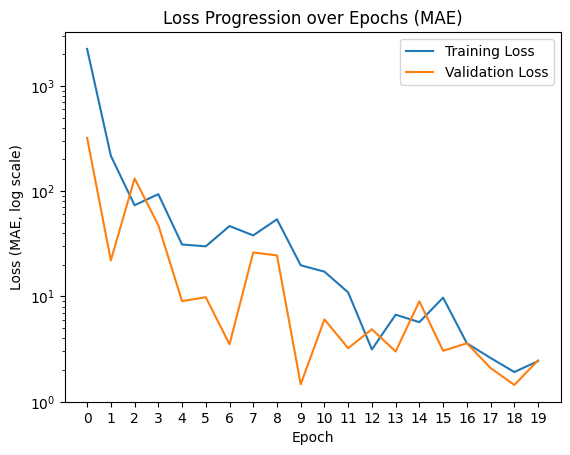

In [ ]:
# Plot the curves
plt.plot(train_losses, label='Training Loss')
plt.plot(global_val_losses, label='Validation Loss')

plt.xticks(range(0, 20))
plt.yscale('log')

plt.xlabel('Epoch')
plt.ylabel('Loss (MAE, log scale)')
plt.legend()
plt.title("Loss Progression over Epochs (MAE)")
plt.show()



 the Huber Loss function for training, evaluate the model on the test set using Huber Loss, and plot the training and validation loss curves.

In [ ]:
#ini
model = GCN(num_layers=4, hidden_size=128)

for batch in train_loader:
    example_batch = batch
    break

rng = jax.random.PRNGKey(0)
params = model.init(rng, example_batch)

#optimizer
optimizer = optax.adam(1e-4)
opt_state = optimizer.init(params)


def loss_huber(params, batch): #loss 3- Payal
    preds = model.apply(params, batch)
    targets = batch.globals
    return jnp.mean(optax.huber_loss(preds.squeeze(), targets.squeeze()))

#step of training (w. opt.)

def train_step(params, opt_state, batch):
    # Changed to use loss_fn_huber
    loss, grads = jax.value_and_grad(loss_huber)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

#loop
num_epochs = 20
train_losses = []
global_val_losses = []

for epoch in range(num_epochs):
    epoch_losses = []
    for batch in train_loader:
        params, opt_state, loss = train_step(params, opt_state, batch)
        epoch_losses.append(loss)
    train_loss = jnp.mean(jnp.array(epoch_losses))

    #validation
    val_losses = []
    for batch in val_loader:

        val_loss = loss_huber(params, batch)
        val_losses.append(val_loss)
    val_loss = jnp.mean(jnp.array(val_losses))
    train_losses.append(train_loss)
    global_val_losses.append(val_loss)
    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}")


Epoch 1: Train Loss=1506.3480, Val Loss=211.2632
Epoch 2: Train Loss=298.4082, Val Loss=205.3866
Epoch 3: Train Loss=159.8497, Val Loss=98.7224
Epoch 4: Train Loss=42.5207, Val Loss=33.6542
Epoch 5: Train Loss=38.9845, Val Loss=78.4323
Epoch 6: Train Loss=33.1632, Val Loss=17.1565
Epoch 7: Train Loss=14.6233, Val Loss=5.2364
Epoch 8: Train Loss=11.9325, Val Loss=13.3616
Epoch 9: Train Loss=12.1962, Val Loss=19.5747
Epoch 10: Train Loss=10.9605, Val Loss=20.9398
Epoch 11: Train Loss=15.1879, Val Loss=6.8084
Epoch 12: Train Loss=6.0471, Val Loss=5.5460
Epoch 13: Train Loss=5.4213, Val Loss=9.4751
Epoch 14: Train Loss=9.3164, Val Loss=1.9403
Epoch 15: Train Loss=9.2644, Val Loss=61.8304
Epoch 16: Train Loss=19.5323, Val Loss=1.2492
Epoch 17: Train Loss=7.4893, Val Loss=2.0050
Epoch 18: Train Loss=12.4375, Val Loss=5.0345
Epoch 19: Train Loss=9.0379, Val Loss=2.6659
Epoch 20: Train Loss=4.6649, Val Loss=1.3313


In [ ]:
#eval on test with Huber loss
test_losses_huber = []
for batch in test_loader:
    loss = loss_huber(params, batch)
    test_losses_huber.append(loss)
print(f"Test Loss (Huber): {jnp.mean(jnp.array(test_losses_huber)):.4f}")

Test Loss (Huber): 1.2331


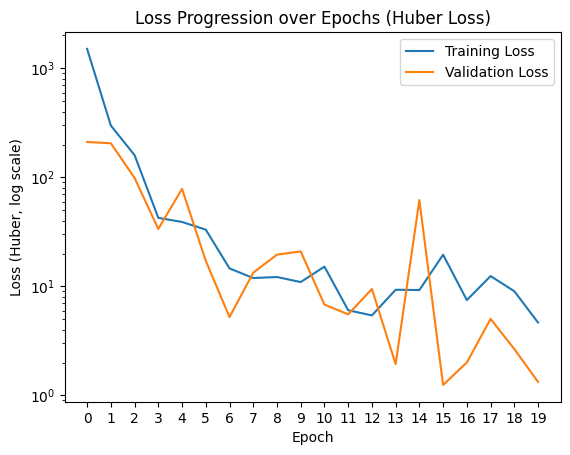

In [ ]:
plt.plot(train_losses, label='Training Loss')
plt.plot(global_val_losses, label='Validation Loss')

plt.xticks(range(0, num_epochs))
plt.yscale('log')

plt.xlabel('Epoch')
plt.ylabel('Loss (Huber, log scale)')
plt.legend()
plt.title("Loss Progression over Epochs (Huber Loss)")
plt.show()